# Layer-vortdiag-topo: native isopycnal initialization

Regenerates this experiment's `input/initial_state.nc` and `input/layer_coord.nc`
using its local YAML and generator. This describes the **ten native layers**;
MOM6's **29-cell z-star diagnostic output** is independently configured in
`MOM_input`. Analysis is in `analysis/inspect_anu_tub.ipynb`.


## Experiment-specific configuration

100 × 100 Cartesian cells at 5000 m spacing, ten fixed-temperature isopycnal
layers with reference interfaces 0, 100, 200, 300, 400, 500, 900, 1300, 1700,
2100 and 2500 m. The YAML below is authoritative. Reference NetCDF files supply
horizontal geometry; their older vertical grid is not the active layer grid.

North is shallower and south deeper: interior `dH/dy=-8e-4`, pivoting at
2500 m at y=250 km, with `BETA=2.66e-11`. Five upper 100 m layers
are retained; five deeper reference layers are each 400 m thick;
local bottom-layer thickness follows the bathymetry. Generate `input/topog.nc`
with `input/generate_topography.py` before running this notebook.


In [1]:
from pathlib import Path
import sys
import json
import warnings
import xarray as xr
import matplotlib.pyplot as plt
%matplotlib inline

# Works from this directory or the experiment root; paths inside YAML are config-relative.
folder = Path('/g/data/fu5/users/rd7475/github/phd/idealised_modelling/mom6_sandbox/mom6-eddy-exp1-layer-vortdiag-topo/initialisation')
sys.path.insert(0, str(folder))
from generate_initial_state import load_config, generate, plot_state
config_path = folder / 'config.yaml'
print(config_path.read_text())

# Paths resolve relative to this file, not the shell working directory.
paths:
  model_directory: ..
  grid: reference/ocean_static.nc
  vertical_grid: reference/Vertical_coordinate.nc
  topography: ../input/topog.nc
  output: ../input/initial_state.nc
eddy:
  centre: domain_midpoint  # midpoint of physical cell-edge domain, m
  aspect_ratio: 1.0
  vertical_tilt: 0.0      # m displacement per m depth; only zero supported
  rotation: cyclonic     # sign(psi0) = -sign(f)
  maximum_speed_radius_m: 50000.0  # 100 km maximum-speed diameter, not cutoff
  surface_speed_m_s: 0.20
  vertical_profile: exponential  # smooth at every depth; no finite cutoff
  e_folding_depth_m: 500.0       # user setting: speed is surface speed / e at this depth
background:
  # Five 100 m layers above 500 m; five 400 m layers below.
  # Temperatures are fixed on material layers, including within the eddy.
  profile: isopycnal
  interface_depths_m: [0, 100, 200, 300, 400, 500, 900, 1300, 1700, 2100, 2500]
  layer_t

## Balance and geometry

The generator uses an exponential velocity profile with 500 m e-folding depth,
evaluated at reference layer centres. The cyclonic eddy displaces isopycnal
interfaces using discrete layer thermal wind. Temperature stays constant in
each layer. Nonzero beta uses the documented centre-f approximate balance.
The printed validation report checks stability, interface ordering and balance.


In [2]:
# Capture warnings once so the instability is prominent without duplicate round-trip warnings.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    output_path, report = generate(config_path)
for message in dict.fromkeys(str(item.message) for item in caught):
    print('WARNING:', message)
print('Generated:', output_path)
print(json.dumps(report, indent=2))
(folder / 'validation.json').write_text(json.dumps(report, indent=2) + '\n')

Generated: /g/data/fu5/users/rd7475/github/phd/idealised_modelling/mom6_sandbox/mom6-eddy-exp1-layer-vortdiag-topo/input/initial_state.nc
{
  "dimensions": {
    "zl": 10,
    "yh": 100,
    "xh": 100,
    "xq": 101,
    "yq": 101,
    "zi": 11
  },
  "psi0_m2_s": 16487.212707001283,
  "rotation": "cyclonic",
  "core_vorticity_s_1": -1.1548620052477165e-05,
  "reference_f_s_1": -9.335e-05,
  "minimum_thickness_m": 1.0110099992743926e-06,
  "surface_error_m": 0.0,
  "bottom_error_m": 0.0,
  "peak_surface_speed_m_s": 0.19985930017521625,
  "peak_surface_radius_m": 49623.58310319802,
  "top_layer_peak_speed_m_s": 0.18084017314101647,
  "vertical_profile": "exponential",
  "e_folding_depth_m": 500.0,
  "exponential_decay_max_error_m_s": 0.0,
  "speed_fraction_at_e_folding_depth": 0.36787944117144233,
  "max_speed_deeper_than_e_folding_depth_m_s": 0.04919822426723071,
  "unstable_vertical_pairs": 0,
  "unstable_columns": 0,
  "minimum_density_increment_kg_m3": 0.3999999999998636,
  "minimum

1180

/g/data/fu5/users/rd7475/github/phd/idealised_modelling/mom6_sandbox/mom6-eddy-exp1-layer-vortdiag-topo/initialisation/generate_initial_state.py:563: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  image = axes[1,0].pcolormesh(np.broadcast_to(ds.yh.values,section.shape),depth[:,:,i],section,shading='nearest',cmap='RdYlBu_r')


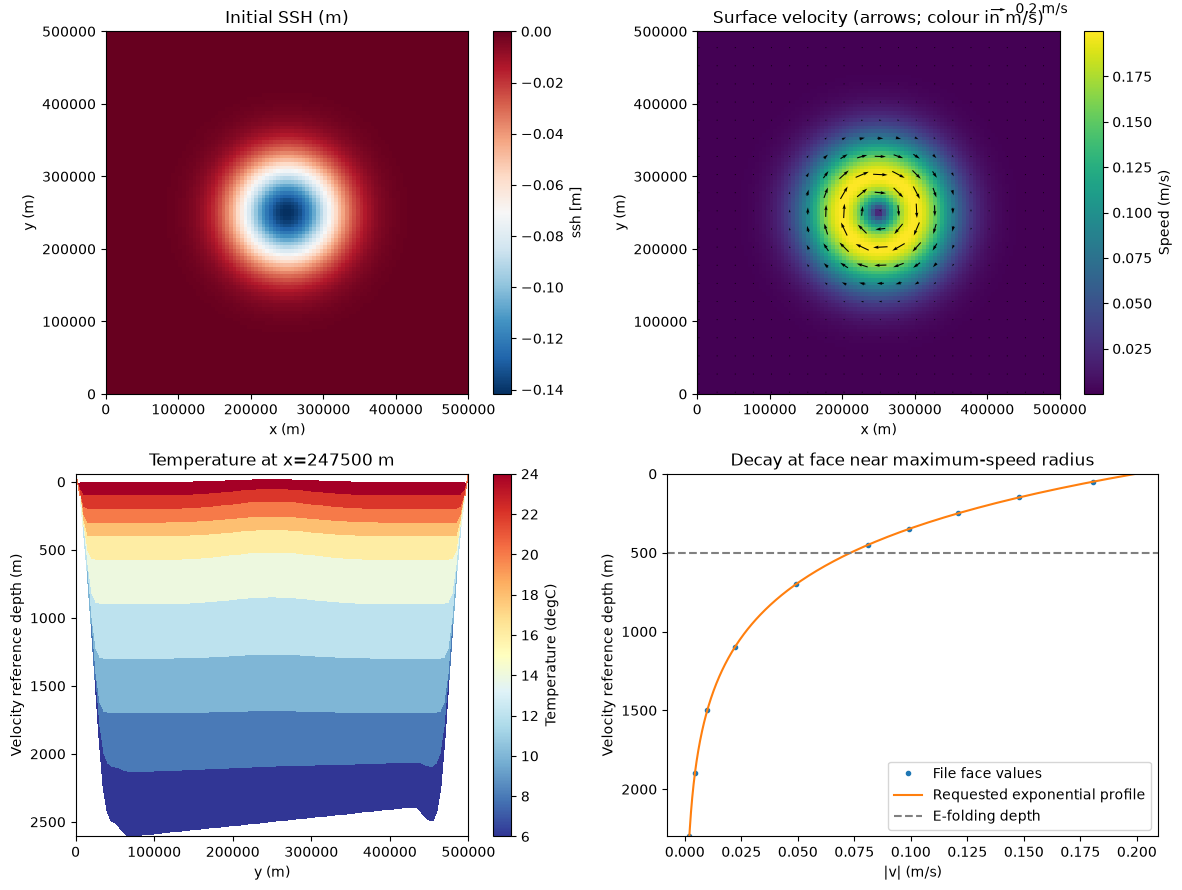

In [3]:
with xr.open_dataset(output_path, decode_times=False) as state:
    fig = plot_state(state)
    plt.show()

## Interpretation and fresh-start handoff

Inspect the validation report before launching a fresh run. This notebook only
generates inputs; it does not integrate MOM6. Use this experiment's run
instructions in `LOCAL_RUN.md`. Daily native-layer and online-remapped output
are specified in `DIAGNOSTICS.md`; native layers and diagnostic z-star cells
are different coordinates.
